This notebook reads in the results of the "judge" CNN applied to MSI data and combines it with a prepared dataset containing ACM-CAP observations in tabular format. The goal is to create a comprehensive dataset that includes both the CNN predictions and the ACM-CAP observations for further analysis.

In [ ]:
import pandas as pd
import numpy as np
import xarray as xr
# set warning to ignore
import warnings
warnings.filterwarnings("ignore", category=UserWarning, append=True)

In [ ]:
stratus_regions = {
    'SEA': {'lat': (-22.5, -2.5), 'lon': (-5, 15)}, # 'lat': (-20, -10), 'lon': (0, 10) original SEA from Klein and Hartmann
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},
    'SEP': {'lat': (-22.5, -2.5), 'lon': (-95, -75)},
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)},
}
stratus_region_names = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}

# Load datasets and prepare for merging

In [ ]:
regions = ['SEA', 'NEA', 'SEP', 'NEP']

## Load the judge dataset

In [ ]:
df_judge_list = []
for region in regions:
    judge_results = f'/home/jmayer/ACI_research/Code/resources_mesoscale_structure/judge_msi_results_{region}.csv'
    df_judge = pd.read_csv(judge_results)
    df_judge['time_mid'] = pd.to_datetime(df_judge['time_mid'])
    df_judge_list.append(df_judge)

In [ ]:
df_judge_list[0]

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,ocean_flag,cats,cert,orbit
0,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.000000,0.397090,0.177294,0.048523,1.0,5.0,0.987178,01005E
1,256.5,2024-08-01 13:33:57.907422976,6.850008,-3.579188,-4.053551,-3.010381,0.000000,0.125214,0.194699,0.027893,1.0,5.0,0.996087,01005E
2,384.5,2024-08-01 13:34:05.971490944,6.752782,-4.100778,-4.575092,-3.531977,0.000000,1.163266,0.292969,0.089417,1.0,5.0,0.997600,01005E
3,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.000000,4.196482,0.607740,0.202087,1.0,5.0,0.979517,01005E
4,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.000000,3.167468,0.615831,0.170166,1.0,5.0,0.862957,01005E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13145,4224.5,2025-11-17 14:02:17.423578112,-3.875664,-19.752005,-20.224516,-19.183390,0.045349,3.322360,0.822761,0.788696,1.0,0.0,0.626594,08365E
13146,4352.5,2025-11-17 14:02:25.487642048,-3.980972,-20.272604,-20.744983,-19.703984,0.101868,5.752044,0.851977,0.717163,1.0,0.0,0.517516,08365E
13147,4480.5,2025-11-17 14:02:33.551705984,-4.086639,-20.793140,-21.265368,-20.224516,0.170410,5.781100,0.927715,0.641541,1.0,3.0,0.393571,08365E
13148,4608.5,2025-11-17 14:02:41.615771008,-4.192802,-21.313596,-21.785653,-20.744983,0.284119,3.856775,0.827008,0.715149,1.0,3.0,0.785090,08365E


In [ ]:
df_judge_list[0].time_mid.min(), df_judge_list[0].time_mid.max()

(Timestamp('2024-08-01 13:33:49.843358976'),
 Timestamp('2025-11-17 14:02:49.679835008'))

<Axes: >

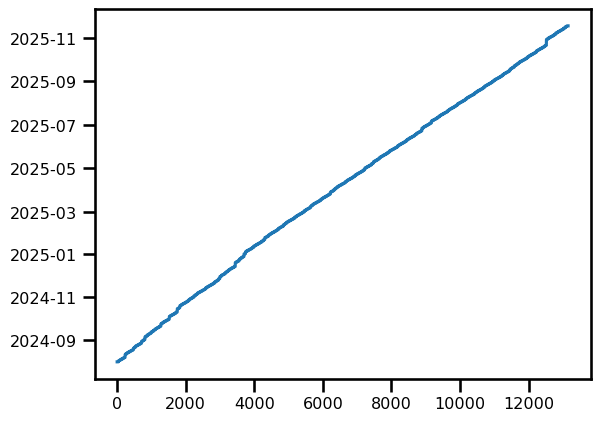

In [ ]:
pd.to_datetime(df_judge_list[0].time_mid).plot()

## Load the ACMCAP dataset

In [ ]:
df_acmcap_list = []
for region in regions:
    dataset_filename = f'/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_StCu_{region}.h5'
    df_acmcap = pd.read_hdf(dataset_filename, key='StCu')

    df_acmcap['acmcap_cloud_fraction'] = np.where(df_acmcap.lwp > 0, 1, 0)
    df_acmcap['rain_fraction'] = np.where(df_acmcap.rain_rate_mean > 0, 1, 0)

    acmcap_variables_of_interest = ['daytime', 'acmcap_cloud_fraction', 'lwp', 'ER', 'ER_passive_perspective', 'Nd', 'lwp_error',
        'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
        'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
        'N_cloudy_pixels', 'rain_fraction', 'rain_rate_mean', 'rain_rate_surface',
        'rain_rate_cbh', 'rain_rate_max', 'rain_rate_subcloud', 'rwc_cbh',
        'rwp', 'rwp_subcloud', 'rain_median_volume_diameter',
        'rain_normalized_number_concentration', 'doppler_velocity_mean']

    # make sure to set variables to NaN where there are no clouds
    for var in acmcap_variables_of_interest:
        if var != 'acmcap_cloud_fraction' and var != 'rain_fraction':
            df_acmcap[var] = df_acmcap[var].where(df_acmcap['acmcap_cloud_fraction'] == 1, np.nan)

    df_acmcap_list.append(df_acmcap)

In [ ]:
df_acmcap_list[0].info()

<class 'pandas.core.frame.DataFrame'>
Index: 1532544 entries, 0 to 1532543
Data columns (total 38 columns):
 #   Column                                Non-Null Count    Dtype         
---  ------                                --------------    -----         
 0   along_track                           1532544 non-null  int64         
 1   time                                  1532544 non-null  datetime64[ns]
 2   latitude                              1532544 non-null  float64       
 3   longitude                             1532544 non-null  float64       
 4   stratus_region_index                  1532544 non-null  int64         
 5   daytime                               969181 non-null   object        
 6   lwp                                   969181 non-null   float32       
 7   ER                                    969181 non-null   float32       
 8   ER_passive_perspective                969181 non-null   float32       
 9   Nd                                    969181 non-nu

## Combine the information of both datasets

In [ ]:
for i, region in enumerate(regions):
    orbits = df_judge_list[i].orbit.unique()
    print(f'missing orbits in judge results for region {region}:')
    for orb in df_acmcap_list[i].orbit.unique():
        if orb not in orbits and orb[-1] in ['D','E']:
            print(orb, '; at ', df_acmcap_list[i][df_acmcap_list[i].orbit == orb].time.iloc[0])

missing orbits in judge results for region SEA:
03914E ; at  2025-02-04 12:47:12.741172992
04692E ; at  2025-03-26 12:46:20.483162112
06637E ; at  2025-07-29 12:45:10.650576512
07026E ; at  2025-08-23 12:45:11.290966528
missing orbits in judge results for region NEA:
01084E ; at  2024-08-06 15:27:34.414684672
01645E ; at  2024-09-11 16:52:21.614170880
02002D ; at  2024-10-04 15:32:50.455765888
02672D ; at  2024-11-16 16:55:13.375744384
03558D ; at  2025-01-12 15:30:35.005820544
05503D ; at  2025-05-17 15:28:47.299148160
05892D ; at  2025-06-11 15:28:30.087864448
07448D ; at  2025-09-19 15:27:55.723453312
07837D ; at  2025-10-14 15:28:01.480685440
08226D ; at  2025-11-08 15:27:53.049655168
missing orbits in judge results for region SEP:
01476E ; at  2024-08-31 20:20:19.601645952
02004E ; at  2024-10-04 18:49:32.776737152
02098E ; at  2024-10-10 19:42:26.704342784
05505E ; at  2025-05-17 18:45:29.381472384
07450E ; at  2025-09-19 18:44:37.360108160
08228E ; at  2025-11-08 18:44:33.871395

### Combine in 128km resolution

In [ ]:
def gini(x) -> float:
    from itertools import combinations
    x = np.array(x, dtype=np.float32)
    if x.sum() == 0:
        return 0.0
    n = len(x)
    diffs = sum(abs(i - j) for i, j in combinations(x, r=2))
    return diffs / (n**2 * x.mean())
                    
def largest_cluster_fraction_1d_scipy(x):
    from scipy.ndimage import label
    x = np.asarray(x)
    rainy = (x > 0).astype(bool)
    if not rainy.any():
        return 0.0, 0
    labeled, n = label(rainy.astype(int))  # 1D connectivity by default
    # sizes for labels 1..n
    sizes = np.bincount(labeled)[1:]
    total = sizes.sum()
    lcf = sizes.max() / total if total > 0 else 0.0
    return float(lcf), n  # return both LCF and number of clusters

In [ ]:
i = 0

# set up dataframe to hold combined results
acmcap_variables_for_additional_measures_per_scene = [
    'cth_m', 'cbh_m', 'N_cloudy_pixels', 'lwp', 'ER', 'Nd',  
    'rwp', 'rain_median_volume_diameter','rain_rate_cbh', 'rwc_cbh']
additional_measures = ['std', 'median', 'perc25', 'perc75', 'perc95', 'perc05']
additional_column_names = []
for var in acmcap_variables_for_additional_measures_per_scene:
    for measure in additional_measures:
        additional_column_names.append(f'{var}_{measure}')
additional_rain_distribution_measures = ['rain_gini', 'rain_lcf', 'rain_n_clusters']
additional_column_names += additional_rain_distribution_measures
df = pd.DataFrame(columns=(['scene_id', 'stratus_region_index'] 
                + list(df_judge.columns) 
                + acmcap_variables_of_interest 
                + additional_column_names
                    ))

for k, region in enumerate(regions):
    df_judge = df_judge_list[k]
    df_acmcap = df_acmcap_list[k]

    j = 0
    unique_orbits = df_judge.orbit.unique()
    print(f'Number of unique orbits in judge results: {len(unique_orbits)}')
    print('Adding ACMCAP data to judge results by taking the mean for each scene...')
    for orbit in unique_orbits:
        j += 1
        print(j, '/',len(unique_orbits), '; ', orbit)
        df_judge_orbit = df_judge[df_judge['orbit']==orbit]
        df_acmcap_orbit = df_acmcap[df_acmcap['orbit']==orbit]

        if df_acmcap_orbit.empty:
            print(f'No matching orbit {orbit} in dataset')
        else:
            for idx, row in df_judge_orbit.iterrows():
                lat_min = row['lat_min']
                lat_max = row['lat_max']
                df_acmcap_scene = df_acmcap_orbit[(df_acmcap_orbit.latitude >= lat_min) & (df_acmcap_orbit.latitude <= lat_max)]

                if len(df_acmcap_scene) > 0:
                    #TODO maybe profiles with high LWP/ Nd error have to be excluded already here before computing the mean?
                    # compute mean for variables of interest
                    df_acmcap_scene_mean = df_acmcap_scene[acmcap_variables_of_interest + ['time']].mean()
                    # add std, max, min, quantiles for selected variables
                    for var in acmcap_variables_for_additional_measures_per_scene:
                        for measure in additional_measures:
                            if measure == 'std':
                                df_acmcap_scene_mean[f'{var}_std'] = df_acmcap_scene[df_acmcap_scene[var] > 0][var].std()
                            elif measure == 'median':
                                df_acmcap_scene_mean[f'{var}_median'] = df_acmcap_scene[var].median()
                            elif measure == 'perc05':
                                df_acmcap_scene_mean[f'{var}_perc05'] = df_acmcap_scene[var].quantile(0.05)
                            elif measure == 'perc10':
                                df_acmcap_scene_mean[f'{var}_perc10'] = df_acmcap_scene[var].quantile(0.10)
                            elif measure == 'perc25':
                                df_acmcap_scene_mean[f'{var}_perc25'] = df_acmcap_scene[var].quantile(0.25)
                            elif measure == 'perc75':
                                df_acmcap_scene_mean[f'{var}_perc75'] = df_acmcap_scene[var].quantile(0.75)
                            elif measure == 'perc90':
                                df_acmcap_scene_mean[f'{var}_perc90'] = df_acmcap_scene[var].quantile(0.90)
                            elif measure == 'perc95':
                                df_acmcap_scene_mean[f'{var}_perc95'] = df_acmcap_scene[var].quantile(0.95)
                    # for spatial distribution of rain we introduce additional measures
                    df_acmcap_scene_mean['rain_gini'] = gini(df_acmcap_scene['rain_rate_mean'].fillna(0).values)
                    rain_lcf, n_cluster = largest_cluster_fraction_1d_scipy(df_acmcap_scene['rain_rate_mean'].fillna(0).values)
                    df_acmcap_scene_mean['rain_lcf'] = rain_lcf
                    df_acmcap_scene_mean['rain_n_clusters'] = n_cluster

                    
                    # sanity check
                    time_diff = abs((df_acmcap_scene_mean.time - row['time_mid']).total_seconds())
                    if time_diff > 1:
                        print(f'Warning: time difference between judge result and acmcap mean is {time_diff} seconds for orbit {orbit}')

                    # combine row and df_acmcap_scene_mean and add to df_comb
                    combined_dict = {**row.to_dict(), **df_acmcap_scene_mean.to_dict()}
                    combined_dict['scene_id'] = i
                    combined_dict['stratus_region_index'] = 2 if region == 'SEP' else 3 if region == 'NEP' else 0 if region == 'SEA' else 1 if region == 'NEA' else -1
                    df.loc[i] = combined_dict
                    i += 1

                else:
                    print(f'No matching latitudes for orbit {orbit} between {lat_min} and {lat_max}')

Number of unique orbits in judge results: 424
Adding ACMCAP data to judge results by taking the mean for each scene...
1 / 424 ;  01005E
2 / 424 ;  01021E
3 / 424 ;  01036E
4 / 424 ;  01052E
5 / 424 ;  01067E
6 / 424 ;  01083E
7 / 424 ;  01098E
8 / 424 ;  01160E
9 / 424 ;  01176E
10 / 424 ;  01192E
11 / 424 ;  01207E
12 / 424 ;  01223E
13 / 424 ;  01238E
14 / 424 ;  01254E
15 / 424 ;  01269E
16 / 424 ;  01300E
17 / 424 ;  01316E
18 / 424 ;  01347E
19 / 424 ;  01363E
20 / 424 ;  01378E
21 / 424 ;  01394E
22 / 424 ;  01409E
23 / 424 ;  01456E
24 / 424 ;  01472E
25 / 424 ;  01487E
26 / 424 ;  01549E
27 / 424 ;  01565E
28 / 424 ;  01581E
29 / 424 ;  01596E
30 / 424 ;  01612E
31 / 424 ;  01627E
32 / 424 ;  01658E
33 / 424 ;  01674E
34 / 424 ;  01689E
35 / 424 ;  01705E
36 / 424 ;  01721E
37 / 424 ;  01736E
38 / 424 ;  01752E
39 / 424 ;  01767E
40 / 424 ;  01783E
41 / 424 ;  01829E
42 / 424 ;  01845E
43 / 424 ;  01861E
44 / 424 ;  01876E
45 / 424 ;  01892E
46 / 424 ;  01907E
47 / 424 ;  0192

In [ ]:
df

,scene_id,stratus_region_index,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,...,rain_rate_cbh_perc05,rwc_cbh_std,rwc_cbh_median,rwc_cbh_perc25,rwc_cbh_perc75,rwc_cbh_perc95,rwc_cbh_perc05,rain_gini,rain_lcf,rain_n_clusters
0,0,0,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,0.397090,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0
1,1,0,256.5,2024-08-01 13:33:57.907422976,6.850008,-3.579188,-4.053551,-3.010381,0.0,0.125214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0
2,2,0,384.5,2024-08-01 13:34:05.971490944,6.752782,-4.100778,-4.575092,-3.531977,0.0,1.163266,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0
3,3,0,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.0,4.196482,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0
4,4,0,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.0,3.167468,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51856,51856,3,2560.5,2025-11-17 23:06:06.455779968,-134.089809,24.561224,24.088340,25.130211,0.0,8.428910,...,2.209834e-07,0.000021,0.000001,0.000001,0.000002,0.000040,1.175981e-06,0.966977,0.833333,2
51857,51857,3,2688.5,2025-11-17 23:06:14.519843968,-134.201069,24.040319,23.567282,24.609319,0.0,4.208299,...,1.552312e-06,NaN,0.000043,0.000043,0.000043,0.000043,4.324405e-05,0.991149,1.000000,1
51858,51858,3,2816.5,2025-11-17 23:06:22.583907968,-134.311787,23.519336,23.046125,24.088340,0.0,4.104455,...,1.552312e-06,NaN,0.000043,0.000043,0.000043,0.000043,4.324405e-05,0.991149,1.000000,1
51859,51859,3,2944.5,2025-11-17 23:06:30.647972032,-134.421768,22.998251,22.528973,23.567282,0.0,8.548552,...,1.054404e-07,0.000026,0.000006,0.000004,0.000024,0.000058,7.142762e-07,0.958463,0.714286,2


In [ ]:
df.to_hdf('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5', key='StCu', mode='w')

In [ ]:
del df_judge_list
del df_acmcap_list
del df_judge
del df_acmcap

### Combine in original resolution

In [ ]:
df_judge

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,ocean_flag,cats,cert,orbit
0,128.5,2024-08-01 22:43:10.132891072,-127.195023,21.939198,21.466846,22.503905,0.0,2.283539,0.705139,0.671753,1,2,0.464485,01011E
1,256.5,2024-08-01 22:43:18.196955008,-127.302673,21.418668,20.946179,21.987439,0.0,1.907596,0.664294,0.613037,1,1,0.295786,01011E
2,384.5,2024-08-01 22:43:26.261018944,-127.409737,20.898064,20.425457,21.466846,0.0,1.412693,0.553464,0.748718,1,1,0.790379,01011E
3,512.5,2024-08-01 22:43:34.325083008,-127.516212,20.377400,19.904655,20.946179,0.0,1.990134,0.580193,0.878357,1,1,0.959265,01011E
4,640.5,2024-08-01 22:43:42.389147456,-127.622272,19.856658,19.383826,20.425457,0.0,1.592384,0.620060,0.932495,1,1,0.955791,01011E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13009,2560.5,2025-11-17 23:06:06.455779968,-134.089809,24.561224,24.088340,25.130211,0.0,8.428910,1.650942,0.067200,1,5,0.947442,08371D
13010,2688.5,2025-11-17 23:06:14.519843968,-134.201069,24.040319,23.567282,24.609319,0.0,4.208299,1.627503,0.089355,1,5,0.931885,08371D
13011,2816.5,2025-11-17 23:06:22.583907968,-134.311787,23.519336,23.046125,24.088340,0.0,4.104455,1.616366,0.085632,1,5,0.895593,08371D
13012,2944.5,2025-11-17 23:06:30.647972032,-134.421768,22.998251,22.528973,23.567282,0.0,8.548552,2.205684,0.118591,1,5,0.819865,08371D


In [ ]:
i = 0

df = pd.DataFrame(columns=(['scene_id', 'stratus_region_index','time'] 
                + list(df_judge.columns) 
                + acmcap_variables_of_interest 
                    ))

for k, region in enumerate(regions):
    df_judge = df_judge_list[k]
    df_acmcap = df_acmcap_list[k]

    j = 0
    unique_orbits = df_judge.orbit.unique()
    print(f'Number of unique orbits in judge results: {len(unique_orbits)}')
    print('Adding ACMCAP data to judge results by taking the mean for each scene...')
    for orbit in unique_orbits:
        j += 1
        print(j, '/',len(unique_orbits), '; ', orbit)
        df_judge_orbit = df_judge[df_judge['orbit']==orbit]
        df_acmcap_orbit = df_acmcap[df_acmcap['orbit']==orbit]

        if df_acmcap_orbit.empty:
            print(f'No matching orbit {orbit} in dataset')
        else:
            for idx, row in df_judge_orbit.iterrows():
                lat_min = row['lat_min']
                lat_max = row['lat_max']
                df_scene = df_acmcap_orbit[(df_acmcap_orbit.latitude >= lat_min) & (df_acmcap_orbit.latitude <= lat_max)]

                if len(df_scene) > 0:
                    for judge_var in df_judge.columns:
                        df_scene[judge_var] = row[judge_var]

                    # sanity check
                    time_diff = abs((df_scene['time'].mean() - row['time_mid']).total_seconds())
                    if time_diff > 2:
                        print(f'Warning: time difference between judge result and acmcap mean is {time_diff} seconds for orbit {orbit}')
                        continue

                    df_scene['scene_id'] = i
                    df_scene['stratus_region_index'] = 2 if region == 'SEP' else 3 if region == 'NEP' else 0 if region == 'SEA' else 1 if region == 'NEA' else -1
                    df = pd.concat([df, df_scene], ignore_index=True)
                    i += 1

                else:
                    print(f'No matching latitudes for orbit {orbit} between {lat_min} and {lat_max}')


Number of unique orbits in judge results: 424
Adding ACMCAP data to judge results by taking the mean for each scene...
1 / 424 ;  01005E
2 / 424 ;  01021E
3 / 424 ;  01036E
4 / 424 ;  01052E
5 / 424 ;  01067E
6 / 424 ;  01083E
7 / 424 ;  01098E
8 / 424 ;  01160E
9 / 424 ;  01176E
10 / 424 ;  01192E
11 / 424 ;  01207E
12 / 424 ;  01223E
13 / 424 ;  01238E
14 / 424 ;  01254E
15 / 424 ;  01269E
16 / 424 ;  01300E
17 / 424 ;  01316E
18 / 424 ;  01347E
19 / 424 ;  01363E
20 / 424 ;  01378E
21 / 424 ;  01394E
22 / 424 ;  01409E
23 / 424 ;  01456E
24 / 424 ;  01472E
25 / 424 ;  01487E
26 / 424 ;  01549E
27 / 424 ;  01565E
28 / 424 ;  01581E
29 / 424 ;  01596E
30 / 424 ;  01612E
31 / 424 ;  01627E
32 / 424 ;  01658E
33 / 424 ;  01674E
34 / 424 ;  01689E
35 / 424 ;  01705E
36 / 424 ;  01721E
37 / 424 ;  01736E
38 / 424 ;  01752E
39 / 424 ;  01767E
40 / 424 ;  01783E
41 / 424 ;  01829E
42 / 424 ;  01845E
43 / 424 ;  01861E
44 / 424 ;  01876E
45 / 424 ;  01892E
46 / 424 ;  01907E
47 / 424 ;  0192

In [ ]:
df

,scene_id,stratus_region_index,time,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,...,rwp_subcloud,rain_median_volume_diameter,rain_normalized_number_concentration,doppler_velocity_mean,along_track,latitude,longitude,N_high_cc,CPR_path_integrated_attenuation,MSI_BT_108
0,0,0,2024-08-01 13:33:41.060923648,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,...,NaN,NaN,NaN,NaN,2716.0,-2.500484,6.887651,0.0,0.0,292.655212
1,0,0,2024-08-01 13:33:41.198970496,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,...,NaN,NaN,NaN,NaN,2717.0,-2.509413,6.885985,0.0,0.0,292.841461
2,0,0,2024-08-01 13:33:41.370731264,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,...,NaN,NaN,NaN,NaN,2718.0,-2.520523,6.883912,0.0,0.0,292.786316
3,0,0,2024-08-01 13:33:41.508773760,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,...,NaN,NaN,NaN,NaN,2719.0,-2.529453,6.882247,0.0,0.0,292.670074
4,0,0,2024-08-01 13:33:41.646816000,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,...,NaN,NaN,NaN,NaN,2720.0,-2.538382,6.880581,0.0,0.0,292.816956
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5857728,51853,3,2025-11-17 23:06:53.590254720,128.5,2025-11-17 23:06:47.028103488,-134.643559,21.939650,21.466115,22.504540,0.0,...,NaN,NaN,NaN,NaN,116.0,21.505654,-134.906777,0.0,0.0,293.362091
5857729,51853,3,2025-11-17 23:06:53.725274752,128.5,2025-11-17 23:06:47.028103488,-134.643559,21.939650,21.466115,22.504540,0.0,...,NaN,NaN,NaN,NaN,117.0,21.496925,-134.908579,0.0,0.0,293.308960
5857730,51853,3,2025-11-17 23:06:53.860294784,128.5,2025-11-17 23:06:47.028103488,-134.643559,21.939650,21.466115,22.504540,0.0,...,NaN,NaN,NaN,NaN,118.0,21.488197,-134.910381,0.0,0.0,293.321655
5857731,51853,3,2025-11-17 23:06:53.995314560,128.5,2025-11-17 23:06:47.028103488,-134.643559,21.939650,21.466115,22.504540,0.0,...,NaN,NaN,NaN,NaN,119.0,21.479468,-134.912182,0.0,0.0,293.219666


In [ ]:
df.to_hdf('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu_1kmres.h5', key='StCu', mode='w')

<Axes: ylabel='Frequency'>

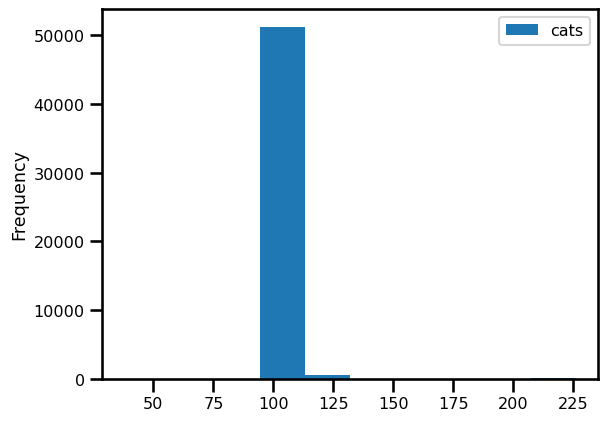

In [ ]:
df[['scene_id','cats']].groupby('scene_id').count().plot.hist()